# Dense rank sweep for frozen Contextual Atlas-DeePC

This notebook uses the **same controller as `baseline_contextual_atlas_deepc.ipynb`**. The 48-chart physical atlas performs localization and graph routing. Nominal control uses the current physical-chart basis. After the unchanged causal terminal-stall trigger, the controller scores 128 frozen contextual prototypes and switches to one cached contextual basis. It scans no Hankel columns and rebuilds no SVD online.

The only swept quantity is the cached affine basis rank. Every integer rank from **20 through 80** is tested on the identical **1,000 seeds, 211--1210**. Contextual prototypes, their 200-column supports, the physical atlas, graph, references, trigger, DeePC objective, constraints, horizon, and strict-success definition are frozen.

Storage is intentionally compact: each rollout retains only its seed, rank, two success flags, and mean/median/p95 end-to-end control time. No rollout trajectories are saved.

In [1]:
import importlib
import json
import math
import os
import sys
import warnings
from dataclasses import asdict, replace
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/atlas_deepc_mpl')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '1')
os.environ['PYTHONWARNINGS'] = 'ignore:Solution may be inaccurate'
warnings.filterwarnings('ignore', message='Solution may be inaccurate.*')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "baseline_atlas_deepc.py").is_file())
SRC = ROOT / 'src'
assert SRC.exists(), 'Run from the atlas_deepc_reacher project root.'
sys.path.insert(0, str(SRC))

import routed_deepc_experiment as routed
import contextual_cluster_atlas_experiment as contextual
contextual = importlib.reload(contextual)

DATA_PATH = ROOT / 'data' / 'select_iid_offline_hankel.npy'
RESULT_ROOT = ROOT / 'experiments' / 'routed_deepc_iid'
PHYSICAL_ATLAS_DIR = RESULT_ROOT / 'clustering_jointconfig48_fresh211_310'
SOURCE_CONTEXTUAL_DIR = RESULT_ROOT / 'contextual_cluster_eval211_710_global128_triggered'
SOURCE_EXTENSION_DIR = RESULT_ROOT / 'contextual_cluster_eval711_1210_global128_triggered'
SOURCE_ARTIFACT_PATH = SOURCE_CONTEXTUAL_DIR / 'contextual_cluster_atlas.npz'
OUTPUT_ROOT = RESULT_ROOT / 'contextual_cluster_dense_rank_1000'
MASTER_ARTIFACT_PATH = OUTPUT_ROOT / 'contextual_cluster_atlas_rank080.npz'

required = [
    DATA_PATH, PHYSICAL_ATLAS_DIR / 'summary.json',
    PHYSICAL_ATLAS_DIR / 'behavioral_atlas.npz',
    SOURCE_CONTEXTUAL_DIR / 'summary.json', SOURCE_EXTENSION_DIR / 'summary.json',
    SOURCE_ARTIFACT_PATH,
]
assert all(path.exists() for path in required), [path for path in required if not path.exists()]
print('Project root:', ROOT)

Project root: /Users/kumiko/Projects/atlas_deepc_reacher


## 1. Controlled rank-only change

The frozen source artifact contains 128 contextual prototypes and their fixed supports $\mathcal J_c$, each with 200 complete Hankel columns. For rank $r$ the offline matrices are

$$
B^{\mathrm{ctx}}_{c,r}=\operatorname{SVD}_r(H(:,\mathcal J_c)-\bar h_c),
\qquad
B^{\mathrm{phys}}_{k,r}=\operatorname{SVD}_r(H(:,\mathcal I_k)-\bar h_k).
$$

A single rank-80 artifact is built from the frozen supports. Lower ranks are leading-component truncations of that shared artifact inside each worker. Thus all ranks use identical prototypes, support columns, affine centers, and SVD ordering. Online deployment always scores only the 128 prototypes and performs no SVD.

In [2]:
RANKS = tuple(range(20, 81))
EVALUATION_SEEDS = list(range(211, 1211))
RUN_EXPERIMENTS = True
WORKERS = 12
OVERWRITE = False
PROGRESS_EVERY = 50

source_payload = json.loads((SOURCE_CONTEXTUAL_DIR / 'summary.json').read_text())
BASE_CONFIG = routed.RoutedDeePCConfig(**source_payload['config'])
CLUSTER_CONFIG = contextual.ContextualClusterConfig(**source_payload['contextual_cluster'])

assert BASE_CONFIG.svd_rank == 60
assert CLUSTER_CONFIG.architecture == 'global_vq'
assert CLUSTER_CONFIG.contextual_clusters == 128
assert CLUSTER_CONFIG.support_columns == 200
assert CLUSTER_CONFIG.activation_mode == 'triggered'
assert CLUSTER_CONFIG.error_threshold == 0.01
assert CLUSTER_CONFIG.stall_window == 15
assert CLUSTER_CONFIG.minimum_progress == 0.001
assert RANKS == tuple(range(20, 81))
assert len(EVALUATION_SEEDS) == len(set(EVALUATION_SEEDS)) == 1000
assert EVALUATION_SEEDS == list(range(211, 1211))
assert max(RANKS) < CLUSTER_CONFIG.support_columns

display(pd.Series({
    'algorithm': 'frozen global-128 triggered contextual Atlas-DeePC',
    'ranks': f'{RANKS[0]}-{RANKS[-1]} inclusive ({len(RANKS)} ranks)',
    'seed range': f'{EVALUATION_SEEDS[0]}-{EVALUATION_SEEDS[-1]}',
    'rollouts per rank': len(EVALUATION_SEEDS),
    'total paired rollouts': len(RANKS) * len(EVALUATION_SEEDS),
    'contextual prototypes scored online': CLUSTER_CONFIG.contextual_clusters,
    'support columns per prototype': CLUSTER_CONFIG.support_columns,
    'online Hankel scans / SVD rebuilds': '0 / 0',
    'saved rollout trajectories': 0,
}))

algorithm                              frozen global-128 triggered contextual Atlas-D...
ranks                                                         20-80 inclusive (61 ranks)
seed range                                                                      211-1210
rollouts per rank                                                                   1000
total paired rollouts                                                              61000
contextual prototypes scored online                                                  128
support columns per prototype                                                        200
online Hankel scans / SVD rebuilds                                                 0 / 0
saved rollout trajectories                                                             0
dtype: object

## 2. Build one shared rank-80 cached atlas

This is an offline preparation step, not part of controller timing. It preserves the baseline contextual prototypes and supports and recomputes only their cached affine matrices at rank 80. Every sweep rank then uses a leading truncation of this same artifact.

In [3]:
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
H = np.load(DATA_PATH, mmap_mode='r')
physical_atlas = routed.load_atlas(PHYSICAL_ATLAS_DIR / 'behavioral_atlas.npz')
source_artifact = contextual.load_contextual_cluster_atlas(SOURCE_ARTIFACT_PATH)

if RUN_EXPERIMENTS and not MASTER_ARTIFACT_PATH.exists():
    rank80_config = replace(BASE_CONFIG, svd_rank=max(RANKS))
    master_artifact = contextual.rebuild_contextual_cluster_atlas_bases(
        H, physical_atlas, source_artifact, rank80_config, CLUSTER_CONFIG,
    )
    contextual.save_contextual_cluster_atlas(MASTER_ARTIFACT_PATH, master_artifact)
else:
    assert MASTER_ARTIFACT_PATH.exists(), (
        'The shared rank-80 artifact is missing; set RUN_EXPERIMENTS=True to build it.'
    )
    master_artifact = contextual.load_contextual_cluster_atlas(MASTER_ARTIFACT_PATH)

assert int(master_artifact['basis_rank']) == 80
assert np.array_equal(master_artifact['support_indices'], source_artifact['support_indices'])
assert np.array_equal(master_artifact['prototype_past'], source_artifact['prototype_past'])
assert np.array_equal(master_artifact['prototype_future'], source_artifact['prototype_future'])
assert master_artifact['matrix_bases'].shape == (128, H.shape[0], 80)
assert master_artifact['physical_matrix_bases'].shape[2] == 80
print('Shared artifact:', MASTER_ARTIFACT_PATH)
print('Contextual basis tensor:', master_artifact['matrix_bases'].shape)
print('Physical basis tensor:', master_artifact['physical_matrix_bases'].shape)

Shared artifact: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/routed_deepc_iid/contextual_cluster_dense_rank_1000/contextual_cluster_atlas_rank080.npz
Contextual basis tensor: (128, 144, 80)
Physical basis tensor: (48, 144, 80)


## 3. Run or resume the dense sweep

Each rank has a compact, seed-level checkpoint. Compatible existing evaluations bootstrap ranks 40, 45, 47, and 60. Rank 60 reuses both completed 500-seed baseline-contextual panels, so it requires no new rollout. Interrupted ranks resume without losing completed seeds.

In [4]:
RANK_DIRS = {rank: OUTPUT_ROOT / f'rank_{rank:03d}' for rank in RANKS}
BOOTSTRAP_DIRS = {
    20: (RESULT_ROOT / 'contextual_cluster_rank_smoke20',),
    40: (RESULT_ROOT / 'contextual_cluster_rank_eval40_211_710',),
    45: (RESULT_ROOT / 'contextual_cluster_rank_eval45_211_710',),
    47: (RESULT_ROOT / 'contextual_cluster_rank_eval47_211_710',),
    60: (SOURCE_CONTEXTUAL_DIR, SOURCE_EXTENSION_DIR),
}
SWEEP_ORDER = tuple(sorted(RANKS, key=lambda rank: (rank not in BOOTSTRAP_DIRS, rank)))

if RUN_EXPERIMENTS:
    for rank in SWEEP_ORDER:
        print(f'\n=== cached contextual Atlas rank {rank} ===', flush=True)
        contextual.run_panel(
            EVALUATION_SEEDS,
            PHYSICAL_ATLAS_DIR,
            RANK_DIRS[rank],
            CLUSTER_CONFIG,
            data_path=DATA_PATH,
            workers=WORKERS,
            overwrite=OVERWRITE,
            control_overrides={'svd_rank': rank},
            shared_artifact_path=MASTER_ARTIFACT_PATH,
            bootstrap_dirs=BOOTSTRAP_DIRS.get(rank, ()),
            save_rollouts=False,
            compact_results=True,
            delete_local_rollouts_after_compaction=True,
            progress_every=PROGRESS_EVERY,
        )
else:
    print(f'Dry run: enable RUN_EXPERIMENTS to run/resume {len(RANKS) * len(EVALUATION_SEEDS):,} paired rollouts.')


=== cached contextual Atlas rank 20 ===



=== cached contextual Atlas rank 40 ===



=== cached contextual Atlas rank 45 ===



=== cached contextual Atlas rank 47 ===



=== cached contextual Atlas rank 60 ===



=== cached contextual Atlas rank 21 ===


... (51 outputs left out)


=== cached contextual Atlas rank 77 ===



=== cached contextual Atlas rank 78 ===



=== cached contextual Atlas rank 79 ===



=== cached contextual Atlas rank 80 ===


## 4. Completion and algorithm audit

Only complete 1,000-seed ranks enter the line plot. The status table also counts unique seeds in an interrupted compact checkpoint.

In [5]:
def checkpoint_count(path):
    if not path.exists():
        return 0
    rows = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
    return len({int(row['seed']) for row in rows})

rank_payloads = {}
status_rows = []
for rank in RANKS:
    output_dir = RANK_DIRS[rank]
    summary_path = output_dir / 'summary.json'
    checkpoint_path = output_dir / 'compact_results.jsonl'
    saved = checkpoint_count(checkpoint_path)
    valid = False
    if summary_path.exists():
        payload = json.loads(summary_path.read_text())
        by_seed = {int(row['seed']): row for row in payload['results']}
        saved = len(set(EVALUATION_SEEDS).intersection(by_seed))
        valid = (
            payload['config'] == asdict(replace(BASE_CONFIG, svd_rank=rank))
            and payload['contextual_cluster'] == asdict(CLUSTER_CONFIG)
            and payload.get('save_rollouts') is False
            and payload.get('compact_results') is True
            and set(by_seed) == set(EVALUATION_SEEDS)
            and len(payload['results']) == len(by_seed) == 1000
        )
        if valid:
            rank_payloads[rank] = {'payload': payload, 'by_seed': by_seed}
    status_rows.append({
        'rank': rank, 'unique saved seeds': saved,
        'missing': len(EVALUATION_SEEDS) - saved,
        'complete and valid': valid,
    })

completion = pd.DataFrame(status_rows)
display(completion.style.hide(axis='index'))
COMPLETE_RANKS = sorted(rank_payloads)
ALL_COMPLETE = COMPLETE_RANKS == list(RANKS)
print(f'Complete ranks: {len(COMPLETE_RANKS)}/{len(RANKS)}')
if ALL_COMPLETE:
    assert all(
        payload['payload']['artifact']['prototype_count'] == 128
        and payload['payload']['artifact']['support_columns'] == 200
        and payload['payload']['artifact']['basis_rank'] == rank
        for rank, payload in rank_payloads.items()
    )
    print('Validated all 61 ranks on the identical ordered 1,000-seed panel.')

rank,unique saved seeds,missing,complete and valid
20,1000,0,True
21,1000,0,True
22,1000,0,True
23,1000,0,True
24,1000,0,True
25,1000,0,True
26,1000,0,True
27,1000,0,True
28,1000,0,True
29,1000,0,True


Complete ranks: 61/61
Validated all 61 ranks on the identical ordered 1,000-seed panel.


## 5. Success-rate and timing plots

The full-range plot shows the low-rank transition. The zoomed plot resolves every rank on the high-success plateau. Timing is shown separately so its scale does not compete with success rate. Every marker is one integer rank evaluated on the same seeds; rank 60 is highlighted as the frozen baseline.

rank,successes,trials,success rate,CI low,CI high,median control time (ms),median p95 control time (ms)
20,5,1000,0.5%,0.2%,1.2%,51.03,95.15
21,5,1000,0.5%,0.2%,1.2%,41.42,70.12
22,5,1000,0.5%,0.2%,1.2%,41.95,70.83
23,10,1000,1.0%,0.5%,1.8%,43.54,73.43
24,27,1000,2.7%,1.9%,3.9%,43.13,72.81
25,24,1000,2.4%,1.6%,3.5%,43.30,72.61
26,66,1000,6.6%,5.2%,8.3%,51.08,87.17
27,297,1000,29.7%,26.9%,32.6%,48.73,83.95
28,381,1000,38.1%,35.1%,41.2%,54.89,116.47
29,424,1000,42.4%,39.4%,45.5%,83.96,166.82


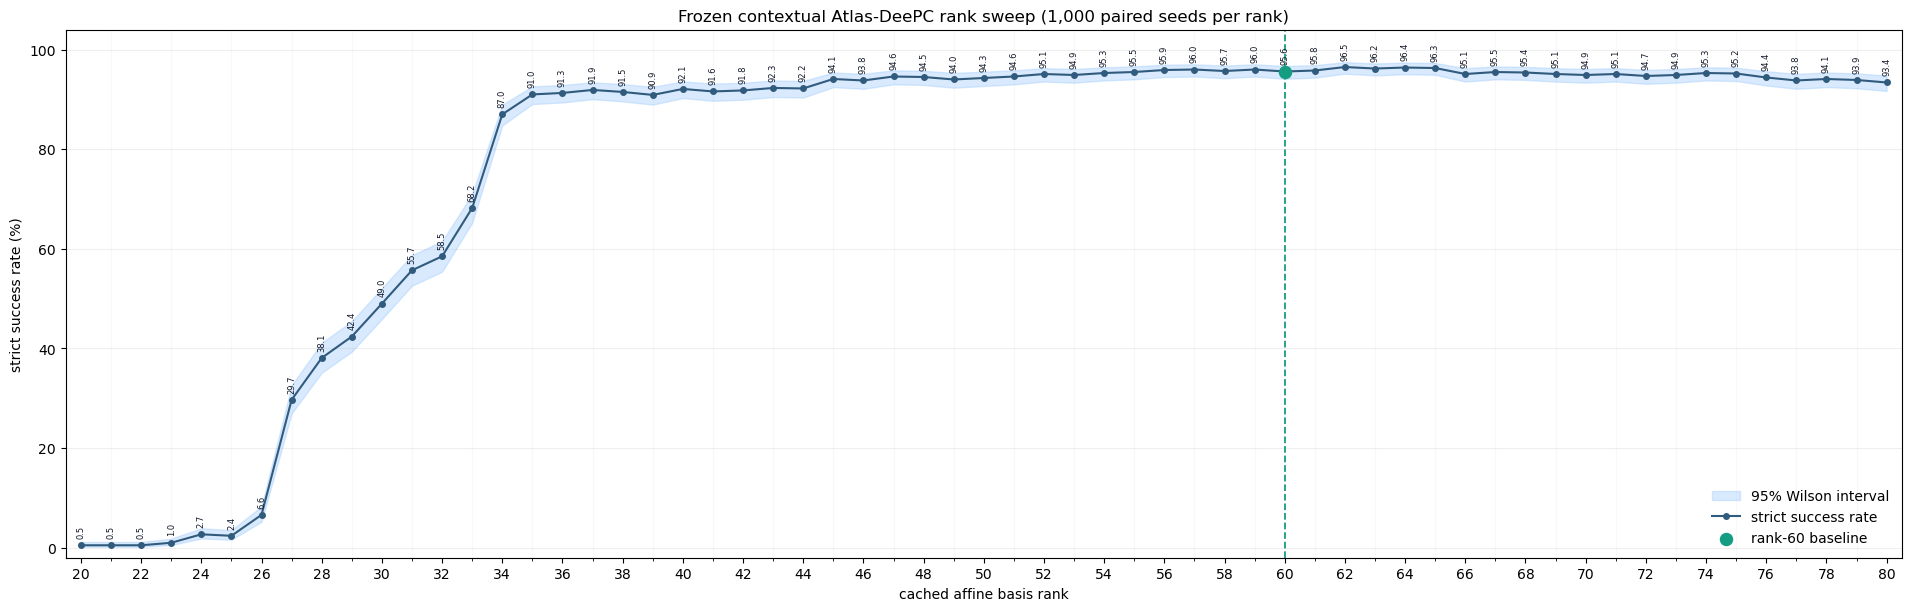

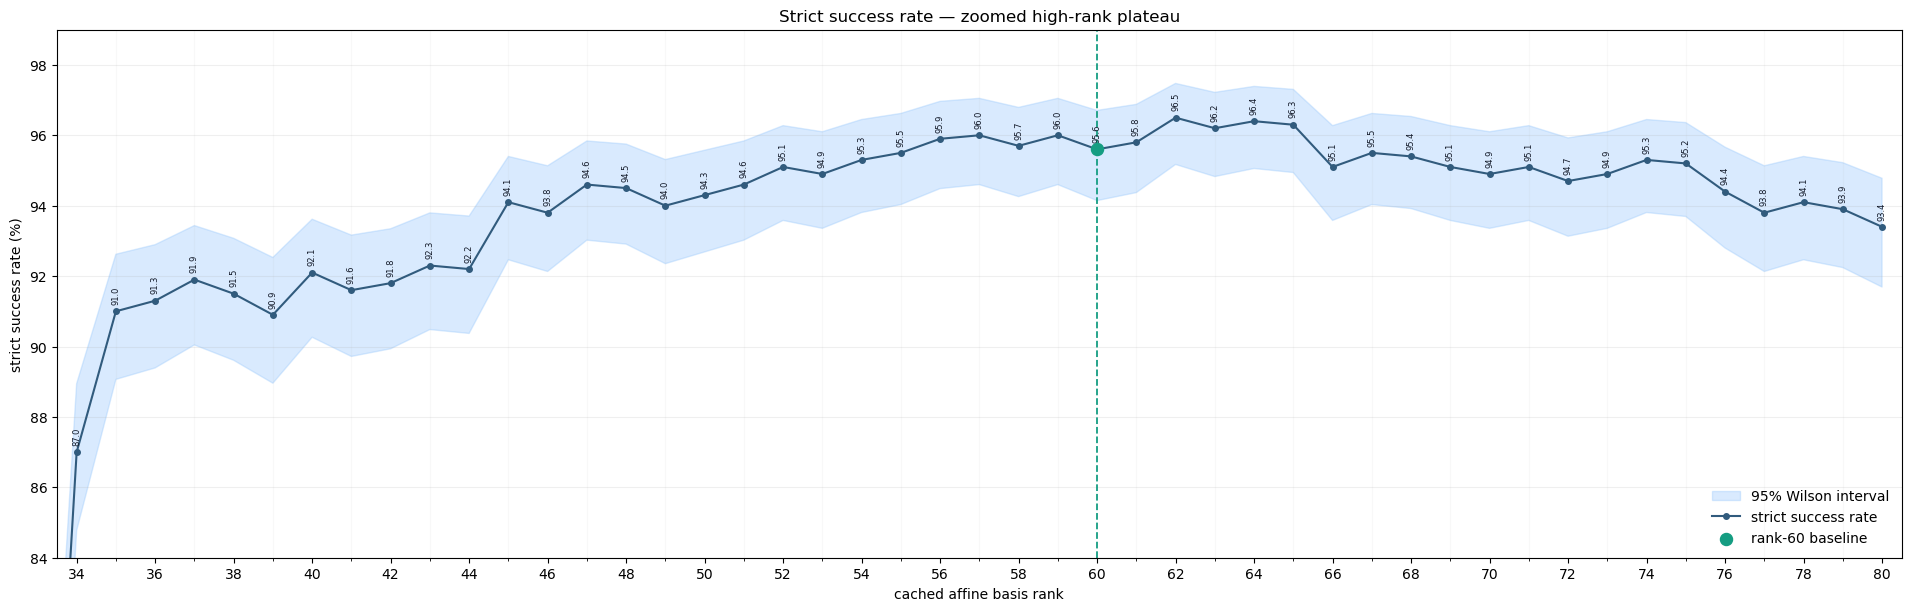

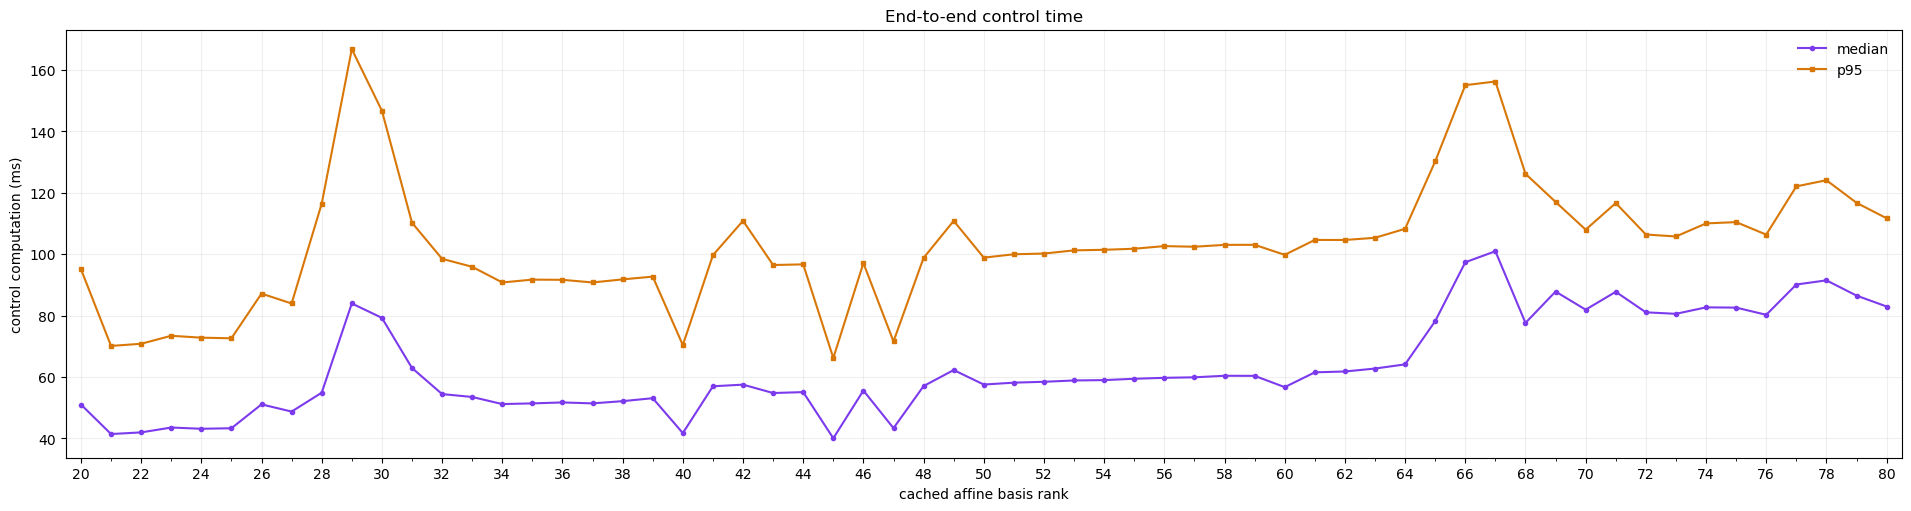

Saved: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/routed_deepc_iid/contextual_cluster_dense_rank_1000/contextual_cached_rank_success_line.png
Saved: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/routed_deepc_iid/contextual_cluster_dense_rank_1000/contextual_cached_rank_success_zoom.png
Saved: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/routed_deepc_iid/contextual_cluster_dense_rank_1000/contextual_cached_rank_timing.png


In [6]:
def strict_success(row):
    return bool(row['success_30'] and row['success_100'])

def wilson_interval(successes, trials, z=1.959963984540054):
    rate = successes / trials
    denominator = 1 + z*z/trials
    center = (rate + z*z/(2*trials)) / denominator
    half = z*np.sqrt(rate*(1-rate)/trials + z*z/(4*trials**2)) / denominator
    return center-half, center+half

summary_rows = []
for rank in COMPLETE_RANKS:
    rows = rank_payloads[rank]['payload']['results']
    successes = sum(strict_success(row) for row in rows)
    low, high = wilson_interval(successes, len(rows))
    summary_rows.append({
        'rank': rank, 'successes': successes, 'trials': len(rows),
        'success rate': successes / len(rows), 'CI low': low, 'CI high': high,
        'median control time (ms)': np.median([row['median_control_compute_ms'] for row in rows]),
        'median p95 control time (ms)': np.median([row['p95_control_compute_ms'] for row in rows]),
    })
rank_summary = pd.DataFrame(summary_rows)
display(rank_summary.style.format({
    'success rate': '{:.1%}', 'CI low': '{:.1%}', 'CI high': '{:.1%}',
    'median control time (ms)': '{:.2f}', 'median p95 control time (ms)': '{:.2f}',
}).hide(axis='index'))

if COMPLETE_RANKS:
    x = rank_summary['rank'].to_numpy()
    rate = 100 * rank_summary['success rate'].to_numpy()
    low = 100 * rank_summary['CI low'].to_numpy()
    high = 100 * rank_summary['CI high'].to_numpy()
    baseline_rate = None
    if 60 in COMPLETE_RANKS:
        baseline_rate = 100 * float(
            rank_summary.loc[rank_summary['rank'] == 60, 'success rate'].iloc[0]
        )

    def decorate_success_axis(ax, *, y_limits, title, annotate=True):
        ax.fill_between(x, low, high, color='#93c5fd', alpha=0.35,
                        label='95% Wilson interval')
        ax.plot(x, rate, '-o', color='#315b7d', linewidth=1.5,
                markersize=4, label='strict success rate')
        if baseline_rate is not None:
            ax.axvline(60, color='#159d82', linewidth=1.3, linestyle='--')
            ax.scatter([60], [baseline_rate], color='#159d82', s=75,
                       zorder=4, label='rank-60 baseline')
        if annotate:
            for rank, value in zip(x, rate):
                if y_limits[0] <= value <= y_limits[1]:
                    ax.annotate(f'{value:.1f}', (rank, value), xytext=(0, 5),
                                textcoords='offset points', ha='center', va='bottom',
                                rotation=90, fontsize=6, color='#111827')
        ax.set(xlim=(19.5, 80.5), ylim=y_limits,
               xlabel='cached affine basis rank',
               ylabel='strict success rate (%)', title=title)
        ax.set_xticks(np.arange(20, 81, 2))
        ax.set_xticks(np.arange(20, 81), minor=True)
        ax.grid(axis='x', which='minor', alpha=0.08)
        ax.grid(axis='y', alpha=0.2)
        ax.legend(frameon=False, loc='lower right')

    fig, ax = plt.subplots(figsize=(19, 6), constrained_layout=True)
    decorate_success_axis(
        ax, y_limits=(-2, 104),
        title=f'Frozen contextual Atlas-DeePC rank sweep ({len(EVALUATION_SEEDS):,} paired seeds per rank)',
    )
    full_success_path = OUTPUT_ROOT / 'contextual_cached_rank_success_line.png'
    fig.savefig(full_success_path, dpi=200, bbox_inches='tight')
    plt.show()

    fig, ax = plt.subplots(figsize=(19, 6), constrained_layout=True)
    decorate_success_axis(
        ax, y_limits=(84, 99),
        title='Strict success rate — zoomed high-rank plateau',
    )
    ax.set_xlim(33.5, 80.5)
    ax.set_xticks(np.arange(34, 81, 2))
    ax.set_xticks(np.arange(34, 81), minor=True)
    zoom_success_path = OUTPUT_ROOT / 'contextual_cached_rank_success_zoom.png'
    fig.savefig(zoom_success_path, dpi=200, bbox_inches='tight')
    plt.show()

    fig, ax = plt.subplots(figsize=(19, 5), constrained_layout=True)
    ax.plot(x, rank_summary['median control time (ms)'], '-o',
            color='#7c3aed', markersize=3, label='median')
    ax.plot(x, rank_summary['median p95 control time (ms)'], '-s',
            color='#d97706', markersize=3, label='p95')
    ax.set(xlim=(19.5, 80.5), xlabel='cached affine basis rank',
           ylabel='control computation (ms)', title='End-to-end control time')
    ax.set_xticks(np.arange(20, 81, 2))
    ax.set_xticks(np.arange(20, 81), minor=True)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    timing_path = OUTPUT_ROOT / 'contextual_cached_rank_timing.png'
    fig.savefig(timing_path, dpi=200, bbox_inches='tight')
    plt.show()

    rank_summary.to_csv(OUTPUT_ROOT / 'contextual_cached_rank_summary.csv', index=False)
    print('Saved:', full_success_path)
    print('Saved:', zoom_success_path)
    print('Saved:', timing_path)
else:
    print('No complete rank is available to plot yet.')

## 6. Paired success changes versus rank 60

McNemar's exact test uses only seeds where a candidate rank and rank 60 disagree. It is reported after the full baseline row exists and does not treat paired outcomes as independent proportions.

rank,rank-only successes,rank-60-only successes,net success change,exact McNemar p
20,0,951,-951,1.051e-286
21,0,951,-951,1.051e-286
22,0,951,-951,1.051e-286
23,0,946,-946,3.362e-285
24,3,932,-929,9.381e-274
25,5,937,-932,3.308e-271
26,6,896,-890,4.381e-257
27,9,668,-659,2.523e-184
28,6,581,-575,2.209e-163
29,7,539,-532,2.429e-149


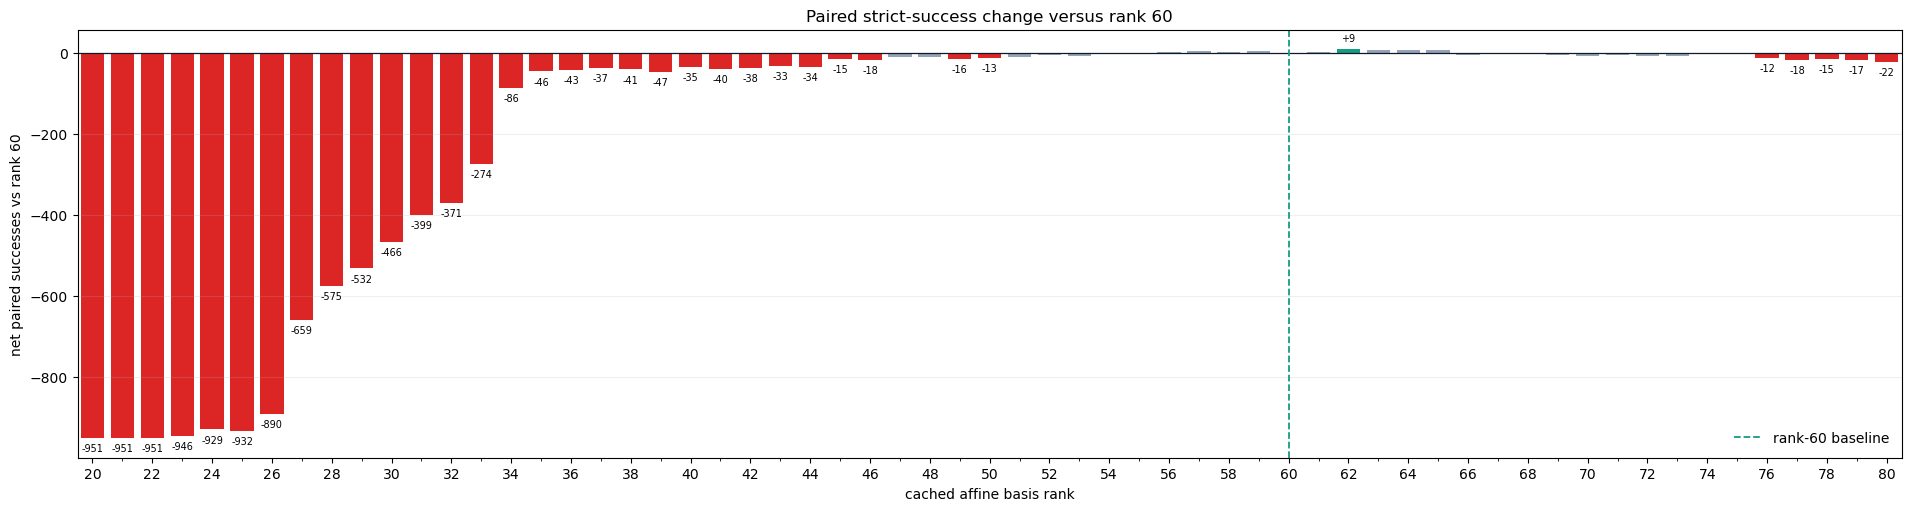

Saved: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/routed_deepc_iid/contextual_cluster_dense_rank_1000/contextual_cached_rank_paired_vs60.png


In [7]:
def exact_mcnemar_p(first_only, second_only):
    discordant = first_only + second_only
    if discordant == 0:
        return 1.0
    tail = sum(math.comb(discordant, k) for k in range(min(first_only, second_only) + 1))
    return min(1.0, 2.0 * tail / (2 ** discordant))

paired_summary = pd.DataFrame()
if 60 in rank_payloads:
    baseline = {
        seed: strict_success(rank_payloads[60]['by_seed'][seed])
        for seed in EVALUATION_SEEDS
    }
    paired_rows = []
    for rank in COMPLETE_RANKS:
        candidate = {
            seed: strict_success(rank_payloads[rank]['by_seed'][seed])
            for seed in EVALUATION_SEEDS
        }
        baseline_only = sum(baseline[s] and not candidate[s] for s in EVALUATION_SEEDS)
        candidate_only = sum(candidate[s] and not baseline[s] for s in EVALUATION_SEEDS)
        paired_rows.append({
            'rank': rank, 'rank-only successes': candidate_only,
            'rank-60-only successes': baseline_only,
            'net success change': candidate_only - baseline_only,
            'exact McNemar p': exact_mcnemar_p(baseline_only, candidate_only),
        })
    paired_summary = pd.DataFrame(paired_rows)
    display(paired_summary.style.format({'exact McNemar p': '{:.4g}'}).hide(axis='index'))
    paired_summary.to_csv(OUTPUT_ROOT / 'contextual_cached_rank_paired_vs60.csv', index=False)

    significant = paired_summary['exact McNemar p'].to_numpy() < 0.05
    net_change = paired_summary['net success change'].to_numpy()
    colors = np.where(
        significant & (net_change > 0), '#159d82',
        np.where(significant & (net_change < 0), '#dc2626', '#94a3b8'),
    )
    fig, ax = plt.subplots(figsize=(19, 5), constrained_layout=True)
    ax.bar(paired_summary['rank'], net_change, color=colors, width=0.78)
    ax.axhline(0, color='#111827', linewidth=0.9)
    ax.axvline(60, color='#159d82', linewidth=1.3, linestyle='--', label='rank-60 baseline')
    for rank, value, is_significant in zip(paired_summary['rank'], net_change, significant):
        if is_significant and value != 0:
            ax.annotate(f'{value:+d}', (rank, value),
                        xytext=(0, 4 if value > 0 else -4), textcoords='offset points',
                        ha='center', va='bottom' if value > 0 else 'top', fontsize=7)
    ax.set(xlim=(19.5, 80.5), xlabel='cached affine basis rank',
           ylabel='net paired successes vs rank 60',
           title='Paired strict-success change versus rank 60')
    ax.set_xticks(np.arange(20, 81, 2))
    ax.set_xticks(np.arange(20, 81), minor=True)
    ax.grid(axis='y', alpha=0.2)
    ax.legend(frameon=False)
    paired_plot_path = OUTPUT_ROOT / 'contextual_cached_rank_paired_vs60.png'
    fig.savefig(paired_plot_path, dpi=200, bbox_inches='tight')
    plt.show()
    print('Saved:', paired_plot_path)
else:
    print('Rank 60 is not complete, so paired tests are deferred.')

## Interpretation

- The line estimates the rank-capacity curve of the **frozen cached contextual Atlas**, not the earlier online top-200 retrieval-and-SVD controller.
- A useful lower rank should preserve paired strict success while reducing end-to-end control time.
- Pointwise Wilson bands describe each proportion; paired McNemar discordances are the appropriate rank-versus-60 outcome test.
- This dense sweep is retrospective on the established 1,000-seed panel. It should not be described as fresh held-out model selection.